Imports, Data Ingestion & Feature Engineering

In [3]:
import sys
from pathlib import Path

# Add project root to Python path so we can import src modules
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_regression

from src.data_loader import load_combined_data, get_chronological_splits
from src.features import add_engineered_features, BASE_FEATURES, ENGINEERED_FEATURES, ALL_FEATURES, TARGET

# Set seed for exact reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# 1. Load combined raw data (2011-2015)
raw_data = load_combined_data(data_dir="../data")

# 2. Add engineered features
df = add_engineered_features(raw_data)

# 3. Get chronological splits
historical_df, data_2014, data_2015 = get_chronological_splits(df)

print(f"✅ Data Successfully Loaded & Transformed!")
print(f" - Total Observations: {len(df)} rows")
print(f" - Historical Dev Set (2011-2013): {len(historical_df)} rows")
print(f" - Update / Drift Window (2014): {len(data_2014)} rows")
print(f" - Final Test Vault (2015): {len(data_2015)} rows")

✅ Loaded: gt_2011.csv (7411 rows)
✅ Loaded: gt_2012.csv (7628 rows)
✅ Loaded: gt_2013.csv (7152 rows)
✅ Loaded: gt_2014.csv (7158 rows)
✅ Loaded: gt_2015.csv (7384 rows)
✅ Data Successfully Loaded & Transformed!
 - Total Observations: 36733 rows
 - Historical Dev Set (2011-2013): 22191 rows
 - Update / Drift Window (2014): 7158 rows
 - Final Test Vault (2015): 7384 rows


Target Distribution Plot (Historical + 2014 Development Window)

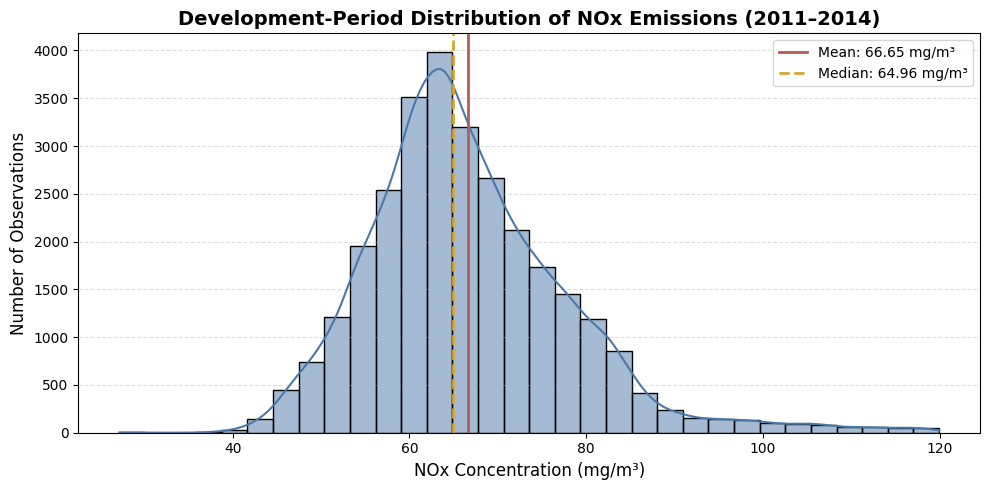

Mean NOx: 66.6523 mg/m³
Median NOx: 64.9640 mg/m³
Standard Deviation: 11.4162 mg/m³


In [4]:
# Create combined development dataset (2011-2014)
dev_data = df[df["YEAR"] <= 2014]

fig, ax = plt.subplots(figsize=(10, 5))

# Plot histogram of NOx
sns.histplot(dev_data[TARGET], bins=32, kde=True, color="#4B78A8", ax=ax)

mean_nox = dev_data[TARGET].mean()
median_nox = dev_data[TARGET].median()

ax.axvline(mean_nox, color="#B95A59", linestyle="-", linewidth=2, label=f"Mean: {mean_nox:.2f} mg/m³")
ax.axvline(median_nox, color="#D9A437", linestyle="--", linewidth=2, label=f"Median: {median_nox:.2f} mg/m³")

ax.set_title("Development-Period Distribution of NOx Emissions (2011–2014)", fontsize=14, fontweight="bold")
ax.set_xlabel("NOx Concentration (mg/m³)", fontsize=12)
ax.set_ylabel("Number of Observations", fontsize=12)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Mean NOx: {mean_nox:.4f} mg/m³")
print(f"Median NOx: {median_nox:.4f} mg/m³")
print(f"Standard Deviation: {dev_data[TARGET].std():.4f} mg/m³")

Year-by-Year Boxplots (First Evidence of Concept Drift)

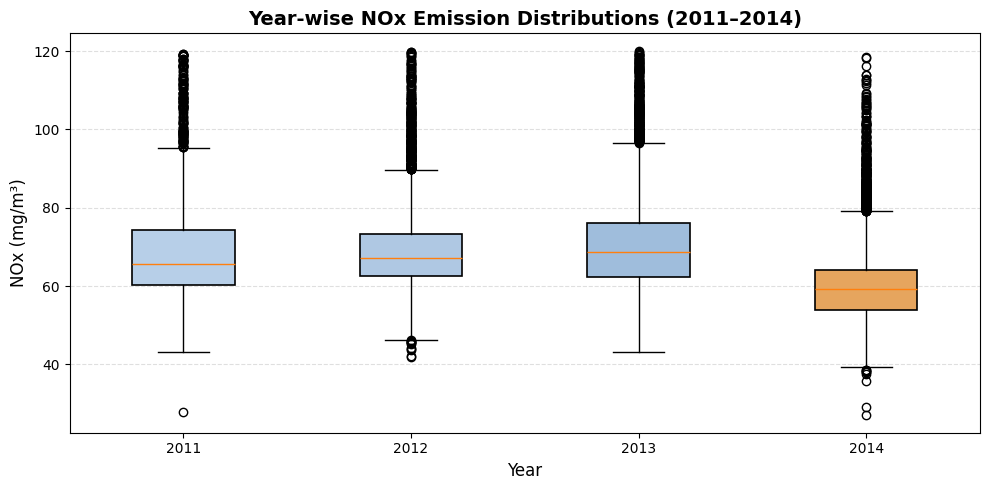


Yearly Mean & Median NOx Summary ->
Year 2011 -> Mean: 67.5754 mg/m³ | Median: 65.5420 mg/m³ | Std: 10.6833
Year 2012 -> Mean: 68.7890 mg/m³ | Median: 67.2465 mg/m³ | Std: 10.2249
Year 2013 -> Mean: 70.0079 mg/m³ | Median: 68.6510 mg/m³ | Std: 12.0482
Year 2014 -> Mean: 60.0669 mg/m³ | Median: 59.2785 mg/m³ | Std: 9.9717


In [6]:
fig, ax = plt.subplots(figsize=(10, 5))

years = [2011, 2012, 2013, 2014]
yearly_nox = [df[df["YEAR"] == yr][TARGET].values for yr in years]

bp = ax.boxplot(yearly_nox, tick_labels=[str(yr) for yr in years], patch_artist=True)

# Styling boxplots
box_colors = ["#B7CFE8", "#AFC8E3", "#9FBDDC", "#E6A55E"]
for patch, color in zip(bp["boxes"], box_colors):
    patch.set_facecolor(color)
    patch.set_linewidth(1.2)

ax.set_title("Year-wise NOx Emission Distributions (2011–2014)", fontsize=14, fontweight="bold")
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("NOx (mg/m³)", fontsize=12)
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# Print yearly statistics
print("\nYearly Mean & Median NOx Summary ->")
for yr in years:
    sub = df[df["YEAR"] == yr][TARGET]
    print(f"Year {yr} -> Mean: {sub.mean():.4f} mg/m³ | Median: {sub.median():.4f} mg/m³ | Std: {sub.std():.4f}")

Feature Importance via Mutual Information (MI)

/var/folders/bg/7gm4yt417px42myyczdlqf1h0000gn/T/ipykernel_23579/2035294362.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=mi_series.values, y=mi_series.index, palette="Blues_r", ax=ax)


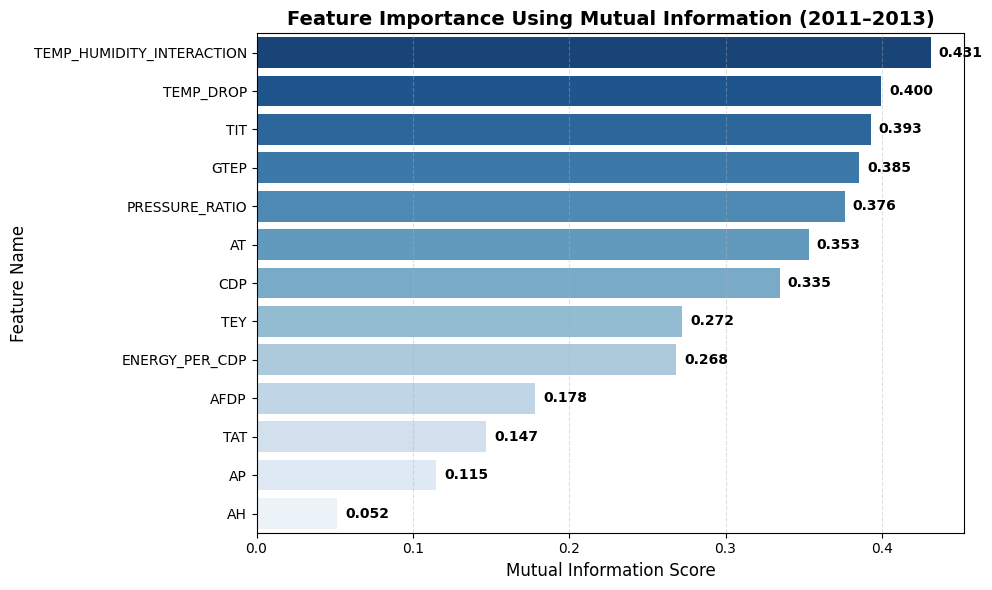


--- Ranked Mutual Information Scores ---
TEMP_HUMIDITY_INTERACTION    0.4312
TEMP_DROP                    0.3996
TIT                          0.3928
GTEP                         0.3855
PRESSURE_RATIO               0.3763
AT                           0.3533
CDP                          0.3347
TEY                          0.2725
ENERGY_PER_CDP               0.2685
AFDP                         0.1783
TAT                          0.1469
AP                           0.1150
AH                           0.0516
dtype: float64


In [7]:
# Compute Mutual Information strictly on historical data (2011-2013) to prevent leakage
X_hist = historical_df[ALL_FEATURES]
y_hist = historical_df[TARGET]

mi_scores = mutual_info_regression(X_hist, y_hist, random_state=RANDOM_STATE)
mi_series = pd.Series(mi_scores, index=ALL_FEATURES).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=mi_series.values, y=mi_series.index, palette="Blues_r", ax=ax)

ax.set_title("Feature Importance Using Mutual Information (2011–2013)", fontsize=14, fontweight="bold")
ax.set_xlabel("Mutual Information Score", fontsize=12)
ax.set_ylabel("Feature Name", fontsize=12)

# Annotate exact scores
for i, v in enumerate(mi_series.values):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontweight="bold")

ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print("\n--- Ranked Mutual Information Scores ---")
print(mi_series.round(4))